# Demo: Orquestador multi-agente

Este notebook muestra el flujo de delegación: **Supervisor → Investigador → Supervisor → Analista → Supervisor → Sintetizador**.

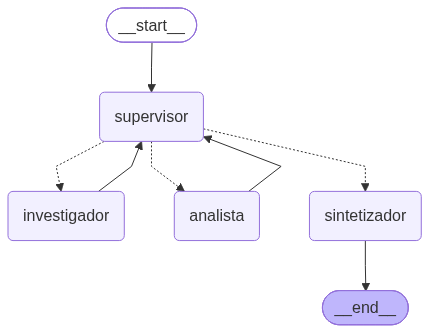

In [1]:
from IPython.display import Image, display
from graph import app

# Diagrama del grafo
display(Image(app.get_graph().draw_mermaid_png()))

## Consulta que necesita dos especialistas
Primero hay que **buscar** reseñas y precios (Investigador) y después **calcular** sentimiento y diferencia de precio (Analista).

In [2]:
pregunta = (
    "¿Qué opinan los clientes de nuestra yerba y estamos caros o baratos frente a la "
    "competencia? Quiero el porcentaje de reseñas positivas y la diferencia de precio."
)

estado_final = None
for paso in app.stream({"messages": [("user", pregunta)]}, stream_mode="values"):
    estado_final = paso
    ultimo = paso["messages"][-1]
    print(f"===== {(ultimo.name or 'usuario').upper()} =====")
    print(ultimo.text)
    print()

===== USUARIO =====
¿Qué opinan los clientes de nuestra yerba y estamos caros o baratos frente a la competencia? Quiero el porcentaje de reseñas positivas y la diferencia de precio.



===== SUPERVISOR =====
-> investigador: Todavía no hay datos, así que primero hay que obtener las reseñas y los precios para que el analista pueda calcular el porcentaje de reseñas positivas y la diferencia de precio.



===== INVESTIGADOR =====
## Reseñas de clientes: yerba mate (marca propia)

Se encontraron **5 reseñas**. **Ninguna trae calificación numérica en las fuentes**, así que ese dato figura como no disponible.

| # | Fuente | Texto completo | Calificación |
|---|--------|----------------|--------------|
| 1 | Google Maps | "La yerba de la marca propia es muy buena, rinde un montón y tiene buen sabor." | No disponible |
| 2 | Instagram | "Excelente yerba, la compro siempre. Recomendable." | No disponible |
| 3 | Google Maps | "Me pareció cara para lo que es, y el paquete vino roto." | No disponible |
| 4 | Facebook | "Buena yerba pero últimamente siempre falta en la góndola." | No disponible |
| 5 | Instagram | "Muy rica, suave y sin palo. Excelente relación precio calidad." | No disponible |

**Cantidad total de reseñas:** 5 (2 de Google Maps, 2 de Instagram y 1 de Facebook).

## Precios actuales: yerba 1 kg

| Supermercado | Fuente | Precio |
|--------------|--------|--------|
| Supermerca

===== SUPERVISOR =====
-> analista: El investigador ya trajo reseñas y precios, y falta calcular el porcentaje de reseñas positivas y la diferencia de precio que pidió el usuario.



===== ANALISTA =====
## 1) Sentimiento de las reseñas de la yerba marca propia

| # | Reseña | Clasificación |
|---|--------|---------------|
| 1 | "…muy buena, rinde un montón y tiene buen sabor." | Positiva |
| 2 | "Excelente yerba, la compro siempre. Recomendable." | Positiva |
| 3 | "Me pareció cara para lo que es, y el paquete vino roto." | Negativa |
| 4 | "Buena yerba pero últimamente siempre falta en la góndola." | Mixta |
| 5 | "Muy rica, suave y sin palo. Excelente relación precio calidad." | Positiva |

- **Positivas:** 3
- **Negativas:** 1
- **Mixtas:** 1
- **Porcentaje de positivas:** 3 de 5 = **60%**

**Criterio para la reseña 4:** la herramienta la devolvió como "neutra", con puntaje 0. Yo la clasifiqué como **mixta**, porque tiene un elogio al producto ("buena yerba") y una queja de otro tipo (falta de stock en la góndola). Los dos elementos se compensan y por eso no la conté como positiva. Si se la contara como positiva, el porcentaje subiría a 80%. Si se la contara co

===== SUPERVISOR =====
-> FINISH: El investigador trajo reseñas y precios concretos, el analista calculó 60% de reseñas positivas (3 de 5) y un precio 1,61% (+$66,67) sobre el promedio de la competencia, y los aportes no se contradicen.



===== SINTETIZADOR =====
## Resumen

**Opinión de los clientes**
- **60% de reseñas positivas** (3 de 5).
- Hay 1 reseña negativa (precio alto y paquete roto) y 1 mixta ("buena yerba pero siempre falta en la góndola").
- Si la mixta se contara como positiva, el porcentaje subiría a 80%.
- Lo más elogiado es el sabor, el rendimiento y la relación precio-calidad. Las quejas son el faltante en góndola, un paquete dañado y un precio percibido como alto.

**Precio frente a la competencia (yerba 1 kg)**

Nuestro precio es $4.200 y el promedio de los competidores es $4.133,33. Estamos **ligeramente más caros: +$66,67 (+1,61%)**.

| Competidor | Precio | Diferencia con nosotros |
|---|---|---|
| SuperAhorro | $3.900 | +$300 (+7,69%) |
| El Barrio | $4.000 | +$200 (+5,00%) |
| MaxiCompra | $4.500 | −$300 (−6,67%) |

**Limitaciones**
- Son solo 5 reseñas y ninguna tiene calificación numérica, así que la clasificación se hizo por el texto.
- No se conoce la marca de la yerba de los competidores, 

## Estado compartido: quién aportó qué

In [3]:
for aporte in estado_final["aportes"]:
    print(f"[{aporte['agente']}] {aporte['instruccion']}")

print()
print("Pasos del supervisor:", estado_final["pasos"])
print("Tarea completa:", estado_final["task_completed"])

[investigador] Buscá las reseñas de clientes sobre la yerba mate de Supermercados del Valle (texto completo y calificación de cada reseña, con la cantidad total) y los precios actuales de la yerba mate equivalente (misma marca o presentación, por ejemplo 1 kg) en nuestro supermercado y en los principales competidores. Devolvé los datos concretos tal como aparecen en las fuentes, sin hacer cálculos. Si algún dato no existe, indicalo como no disponible.
[analista] Con los datos ya obtenidos, hacé dos cálculos. 1) Análisis de sentimiento de las 5 reseñas de la yerba marca propia de Supermercados del Valle. Clasificá cada una como positiva, negativa o mixta según su texto, ya que no tienen calificación numérica. Las reseñas son: (1) 'La yerba de la marca propia es muy buena, rinde un montón y tiene buen sabor.' (2) 'Excelente yerba, la compro siempre. Recomendable.' (3) 'Me pareció cara para lo que es, y el paquete vino roto.' (4) 'Buena yerba pero últimamente siempre falta en la góndola.'